In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('messy_online_retail_3000.csv')

print("--- 1. DATASET OVERVIEW ---")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nFirst 3 rows:")
print(df.head(3))

print("\n--- MISSING VALUES ---")
print(df.isnull().sum())

print(f"\n--- DUPLICATES ---")
print(f"Exact duplicate rows: {df.duplicated().sum()}")

--- 1. DATASET OVERVIEW ---
Shape: 3000 rows, 10 columns

First 3 rows:
  InvoiceNo StockCode            Description Category  Quantity  \
0    500449   SKU1171         Perfume - Gold   Beauty       8.0   
1    501530   SKU1043    Watering Can - Blue   Garden       1.0   
2    501557   SKU1196  Running Shoes - Black  Apparel       7.0   

           InvoiceDate UnitPrice CustomerID         Country  TotalPrice  
0  2023-05-06 16:48:36     18.07        NaN       Australia      144.56  
1     09/28/2023 01:58     48.65      11579  United Kingdom       48.65  
2  2023-09-22 03:19:07     29.17      10089  United Kingdom      204.19  

--- MISSING VALUES ---
InvoiceNo        0
StockCode       54
Description      0
Category         0
Quantity        57
InvoiceDate     13
UnitPrice       24
CustomerID     244
Country         87
TotalPrice     202
dtype: int64

--- DUPLICATES ---
Exact duplicate rows: 74


In [23]:
# A. Drop duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# B. Clean Category (strip whitespace, title case, handle placeholders)
df['Category'] = df['Category'].astype(str).str.strip().str.title()
df['Category'] = df['Category'].replace(['Nan', 'None'], np.nan)

# C. Standardize Country names
country_mapping = {
    'uk': 'United Kingdom', 'UK': 'United Kingdom', 'UK ': 'United Kingdom',
    'usa': 'United States', 'USA': 'United States', 'U.S.A.': 'United States',
    'germany': 'Germany'
}
df['Country'] = df['Country'].astype(str).str.strip().replace(country_mapping)
df['Country'] = df['Country'].replace(['Nan', 'None'], np.nan)

print("✅ Text cleaning complete. Unique Categories:", df['Category'].dropna().unique())

✅ Text cleaning complete. Unique Categories: ['Beauty' 'Garden' 'Apparel' 'Electronics' 'Home & Kitchen' 'Toys & Games'
 'Stationery']


In [24]:
# A. Clean UnitPrice (remove symbols, coerce to float, handle outliers)
def clean_unit_price(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).replace('$', '').replace('USD', '').strip()
    try:
        price = float(val_str)
        return price if 0 <= price <= 2000 else np.nan
    except ValueError:
        return np.nan

df['UnitPrice'] = df['UnitPrice'].apply(clean_unit_price)

# B. Clean Quantity
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df.loc[(df['Quantity'] > 1000) | (df['Quantity'] < -100), 'Quantity'] = np.nan

# C. Parse mixed InvoiceDate formats safely
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')

# D. Clean CustomerID
df['CustomerID'] = df['CustomerID'].replace(['UNKNOWN', 'N/A', 'nan'], np.nan)

# E. Recalculate TotalPrice accurately
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

print("✅ Numerical & Date cleaning complete. Cleaned shape:", df.shape)

✅ Numerical & Date cleaning complete. Cleaned shape: (2926, 10)


In [25]:
# Extract temporal features
df['Year'] = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()
df['Hour'] = df['InvoiceDate'].dt.hour
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')

# Flag cancellations ('C' prefix in InvoiceNo or negative quantity)
df['IsCancellation'] = df['InvoiceNo'].astype(str).str.startswith('C') | (df['Quantity'] < 0)

print("✅ Feature engineering complete.")

✅ Feature engineering complete.


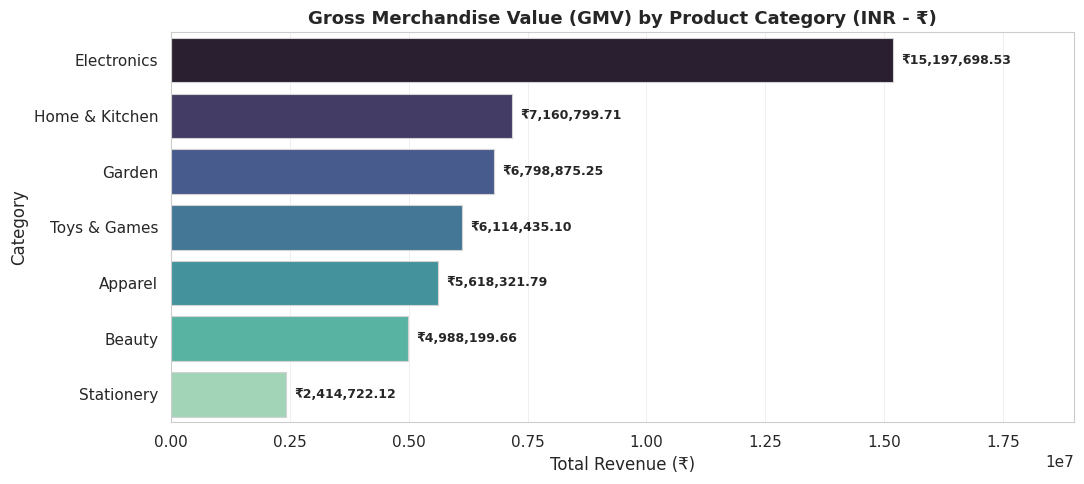

In [51]:
USD_TO_INR = 95.75
valid_df['UnitPrice_INR']  = valid_df['UnitPrice']  * USD_TO_INR
valid_df['TotalPrice_INR'] = valid_df['TotalPrice'] * USD_TO_INR

category_gmv_inr = (valid_df.groupby('Category')['TotalPrice_INR']
                            .sum()
                            .reset_index()
                            .sort_values('TotalPrice_INR', ascending=False))

plt.figure(figsize=(11, 5))
ax = sns.barplot(
    data=category_gmv_inr,
    x='TotalPrice_INR',
    y='Category',
    hue='Category',
    palette='mako',
    legend=False,
    edgecolor='#D3D3D3',   # ← light grey outline
    linewidth=0.8
)

plt.title('Gross Merchandise Value (GMV) by Product Category (INR - ₹)',
          fontsize=13, fontweight='bold')
plt.xlabel('Total Revenue (₹)')
plt.ylabel('Category')

# Faint gridlines (only vertical)
ax.grid(True, axis='x', color='#E5E5E5', linewidth=0.6, alpha=0.7)
ax.set_axisbelow(True)     # put grid behind bars

# Light axis spines
for spine in ax.spines.values():
    spine.set_color('#CCCCCC')    # light grey instead of black
    spine.set_linewidth(0.8)

# Value labels
for p in ax.patches:
    w = p.get_width()
    if w > 0:
        ax.annotate(
            f"₹{w:,.2f}",
            (w, p.get_y() + p.get_height() / 2),
            ha='left', va='center',
            xytext=(6, 0), textcoords='offset points',
            fontsize=9, fontweight='semibold'
        )

plt.xlim(0, category_gmv_inr['TotalPrice_INR'].max() * 1.25)
plt.tight_layout()
plt.show()

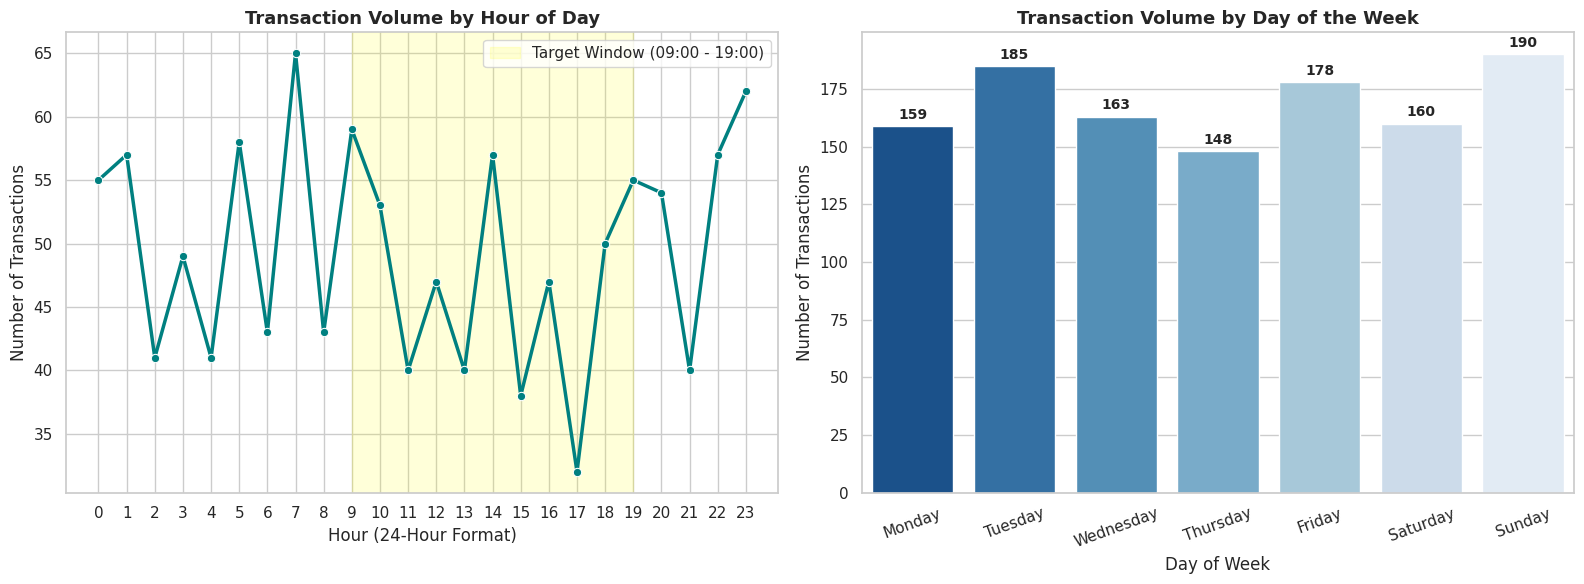

In [36]:
# Parse Dates safely
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')

# Extract Hour and Day of Week
df['Hour'] = df['InvoiceDate'].dt.hour
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()

# Filter valid transactions (ignoring null dates or cancellations if needed)
valid_df = df[df['InvoiceDate'].notnull()].copy()

# Group by Hour and Day of Week
hourly_traffic = valid_df.groupby('Hour').size().reset_index(name='Transaction_Count')

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily_traffic = valid_df.groupby('DayOfWeek').size().reindex(day_order).reset_index(name='Transaction_Count')

# Create Subplots for Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Peak Traffic Hours (09:00 to 19:00 or full 24-hour distribution)
ax1 = sns.lineplot(
    data=hourly_traffic,
    x='Hour',
    y='Transaction_Count',
    marker='o',
    color='teal',
    linewidth=2.5,
    ax=axes[0]
)
axes[0].set_title('Transaction Volume by Hour of Day', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Hour (24-Hour Format)')
axes[0].set_ylabel('Number of Transactions')
axes[0].set_xticks(range(0, 24))

# Highlight target window between 09:00 and 19:00
axes[0].axvspan(9, 19, color='yellow', alpha=0.15, label='Target Window (09:00 - 19:00)')
axes[0].legend(loc='upper right')

# 2. Peak Days of the Week
ax2 = sns.barplot(
    data=daily_traffic,
    x='DayOfWeek',
    y='Transaction_Count',
    hue='DayOfWeek',
    palette='Blues_r',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Transaction Volume by Day of the Week', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Number of Transactions')
plt.xticks(rotation=20)

for p in ax2.patches:
    height = p.get_height()
    if height > 0:
        ax2.annotate(f"{int(height):,}", (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', xytext=(0, 3), textcoords='offset points', fontsize=10, fontweight='semibold')

plt.tight_layout()
plt.show()

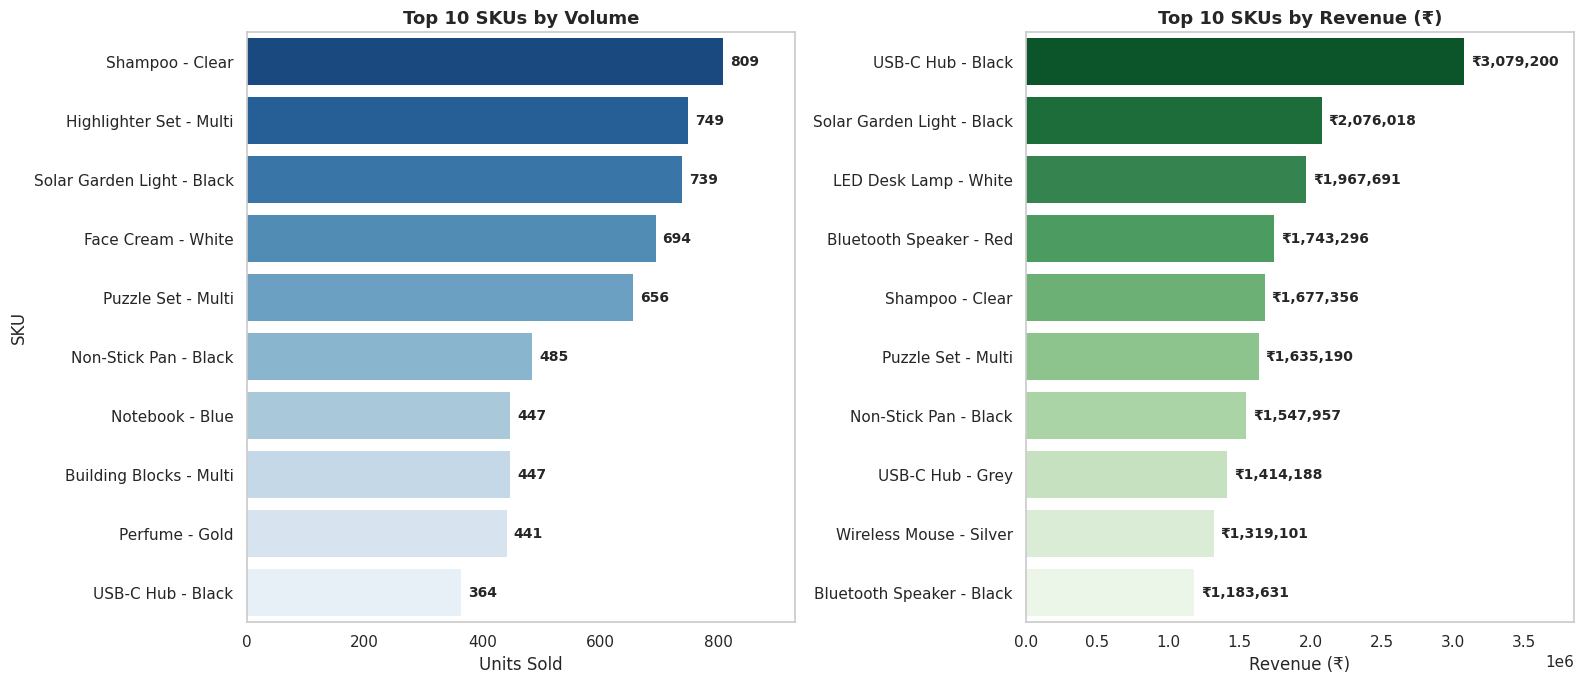

In [49]:
# --- Exchange rate ---
USD_TO_INR = 83.0     # adjust to current rate if you like

# --- Aggregate ---
sku_performance = valid_df.groupby('Description').agg(
    Total_Volume=('Quantity', 'sum'),
    Total_Revenue=('TotalPrice', 'sum')
).reset_index()

# Convert revenue to INR
sku_performance['Total_Revenue_INR'] = sku_performance['Total_Revenue'] * USD_TO_INR

top_volume  = sku_performance.sort_values('Total_Volume',        ascending=False).head(10)
top_revenue = sku_performance.sort_values('Total_Revenue_INR',   ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ---------- Chart 1: Volume ----------
sns.barplot(
    data=top_volume,
    x='Total_Volume',
    y='Description',
    hue='Description',
    palette='Blues_r',
    legend=False,
    edgecolor='none',
    ax=axes[0]
)
axes[0].set_title('Top 10 SKUs by Volume', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Units Sold')
axes[0].set_ylabel('SKU')
axes[0].grid(False)

for p in axes[0].patches:
    w = p.get_width()
    if w > 0:
        axes[0].annotate(
            f"{int(w):,}",
            (w, p.get_y() + p.get_height() / 2),
            ha='left', va='center',
            xytext=(5, 0), textcoords='offset points',
            fontsize=10, fontweight='bold'
        )

# ---------- Chart 2: Revenue (INR) ----------
sns.barplot(
    data=top_revenue,
    x='Total_Revenue_INR',
    y='Description',
    hue='Description',
    palette='Greens_r',
    legend=False,
    edgecolor='none',
    ax=axes[1]
)
axes[1].set_title('Top 10 SKUs by Revenue (₹)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Revenue (₹)')
axes[1].set_ylabel('')
axes[1].grid(False)

for p in axes[1].patches:
    w = p.get_width()
    if w > 0:
        axes[1].annotate(
            f"₹{w:,.0f}",                       # ← ₹ instead of $
            (w, p.get_y() + p.get_height() / 2),
            ha='left', va='center',
            xytext=(5, 0), textcoords='offset points',
            fontsize=10, fontweight='bold'
        )

# Extend x-axis so labels don't get cut
axes[0].set_xlim(0, top_volume['Total_Volume'].max() * 1.15)
axes[1].set_xlim(0, top_revenue['Total_Revenue_INR'].max() * 1.25)

plt.tight_layout()
plt.show()